In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATA_PATH = "../datasets/ml/chronic_disease/Data Warehouse Multiclass.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Dataset loaded successfully.
Rows: 280,985
Columns: 39


In [3]:
df.head()

,composite_key,age_level,gender,bmi_level,smoking,diabetes,age,age_normalized,bmi,hypertension,heart_disease,HbA1c_level,glucose,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,high_blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,source_dataset,disease_flags,sublabel,label
0,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,9,0.080460,19.20,0.0,0.0,5.8,158.0,214.703704,6.864403,246.703704,High,No,High,Yes,Yes,152.481481,No,Low,8.219098,11.168096,135.380192,89.539936,14.777636,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
1,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,22.55,0.0,0.0,6.6,159.0,214.703704,6.864403,246.703704,High,No,High,Yes,Yes,152.481481,No,Low,8.219098,11.168096,135.380192,89.539936,14.777636,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
2,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,22.89,0.0,0.0,4.0,126.0,214.703704,6.864403,246.703704,High,No,High,Yes,Yes,152.481481,No,Low,8.219098,11.168096,135.380192,89.539936,14.777636,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
3,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,23.12,0.0,0.0,6.2,85.0,214.703704,6.864403,246.703704,High,No,High,Yes,Yes,152.481481,No,Low,8.219098,11.168096,135.380192,89.539936,14.777636,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
4,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,4,0.022989,19.61,0.0,0.0,5.7,155.0,214.703704,6.864403,246.703704,High,No,High,Yes,Yes,152.481481,No,Low,8.219098,11.168096,135.380192,89.539936,14.777636,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 280985 entries, 0 to 280984
Data columns (total 39 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   composite_key         280985 non-null  object 
 1   age_level             280985 non-null  object 
 2   gender                280985 non-null  object 
 3   bmi_level             280985 non-null  object 
 4   smoking               280985 non-null  object 
 5   diabetes              280985 non-null  object 
 6   age                   280985 non-null  int64  
 7   age_normalized        280985 non-null  float64
 8   bmi                   280985 non-null  float64
 9   hypertension          280985 non-null  float64
 10  heart_disease         280985 non-null  float64
 11  HbA1c_level           280985 non-null  float64
 12  glucose               280985 non-null  float64
 13  cholesterol           280985 non-null  float64
 14  sleep_hours           280985 non-null  float64
 15  

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
composite_key,280985,192,Middle_Female_Overweight_Never_No,6097,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_level,280985,4,Mature,87632,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,280985,2,Female,148763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi_level,280985,4,Obese,98377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoking,280985,3,Never,127764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diabetes,280985,2,No,180351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,280985.0,NaN,NaN,NaN,49.665865,21.68235,2.0,32.0,50.0,67.0,89.0
age_normalized,280985.0,NaN,NaN,NaN,0.547883,0.249222,0.0,0.344827,0.551724,0.747126,1.0
bmi,280985.0,NaN,NaN,NaN,27.490663,7.040373,10.01,22.1,27.32,32.7,95.69
hypertension,280985.0,NaN,NaN,NaN,0.128218,0.187346,0.0,0.0,0.071429,0.217063,1.0


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 2284


In [7]:
print(df["label"].value_counts())
print()
print(df["label"].value_counts(normalize=True).mul(100).round(2))

label
Abnormal    174101
Normal      106884
Name: count, dtype: int64

label
Abnormal    61.96
Normal      38.04
Name: proportion, dtype: float64


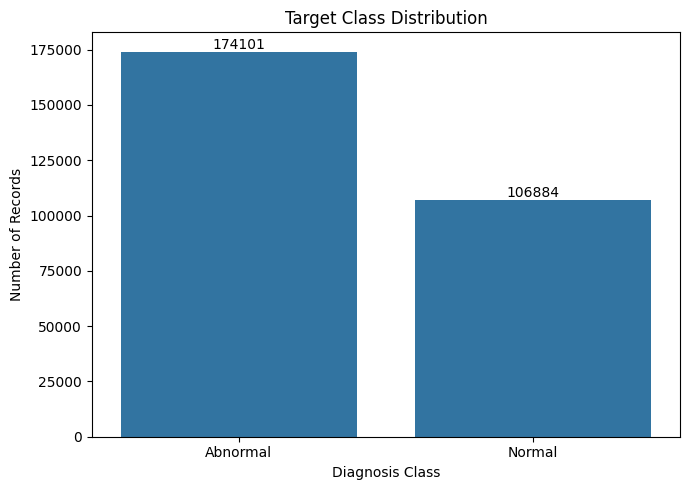

In [8]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index
)

plt.title("Target Class Distribution")
plt.xlabel("Diagnosis Class")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [9]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Categorical columns:")
for col in categorical_cols:
    print(f"- {col}: {df[col].nunique()} unique values")

Categorical columns:
- composite_key: 192 unique values
- age_level: 4 unique values
- gender: 2 unique values
- bmi_level: 4 unique values
- smoking: 3 unique values
- diabetes: 2 unique values
- physical_activity: 3 unique values
- family_history: 2 unique values
- stress_level: 3 unique values
- low_hdl_cholesterol: 2 unique values
- high_ldl_cholesterol: 2 unique values
- high_blood_pressure: 2 unique values
- sugar_consumption: 3 unique values
- education_level: 3 unique values
- employment_status: 3 unique values
- source_dataset: 3 unique values
- disease_flags: 8 unique values
- sublabel: 8 unique values
- label: 2 unique values


In [10]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical columns:")
for col in numerical_cols:
    print(f"- {col}")

Numerical columns:
- age
- age_normalized
- bmi
- hypertension
- heart_disease
- HbA1c_level
- glucose
- cholesterol
- sleep_hours
- triglycerides
- blood_pressure
- crp_level
- homocysteine_level
- systolic_bp
- diastolic_bp
- alcohol_intake
- salt_intake
- heart_rate
- hdl
- ldl


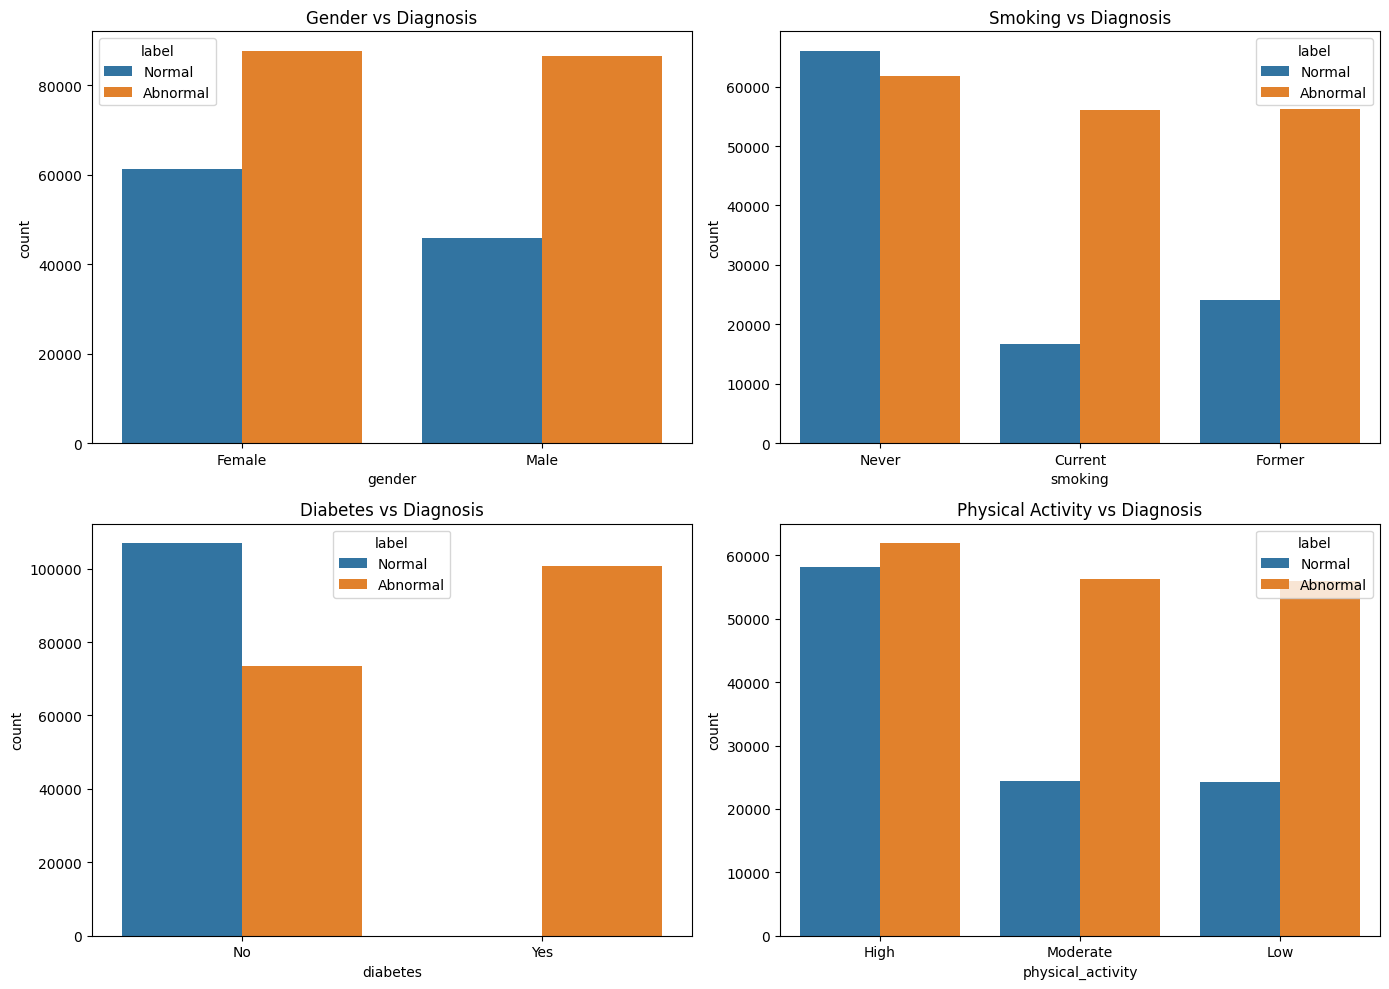

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x="gender", hue="label", ax=axes[0, 0])
axes[0, 0].set_title("Gender vs Diagnosis")

sns.countplot(data=df, x="smoking", hue="label", ax=axes[0, 1])
axes[0, 1].set_title("Smoking vs Diagnosis")

sns.countplot(data=df, x="diabetes", hue="label", ax=axes[1, 0])
axes[1, 0].set_title("Diabetes vs Diagnosis")

sns.countplot(data=df, x="physical_activity", hue="label", ax=axes[1, 1])
axes[1, 1].set_title("Physical Activity vs Diagnosis")

plt.tight_layout()
plt.show()

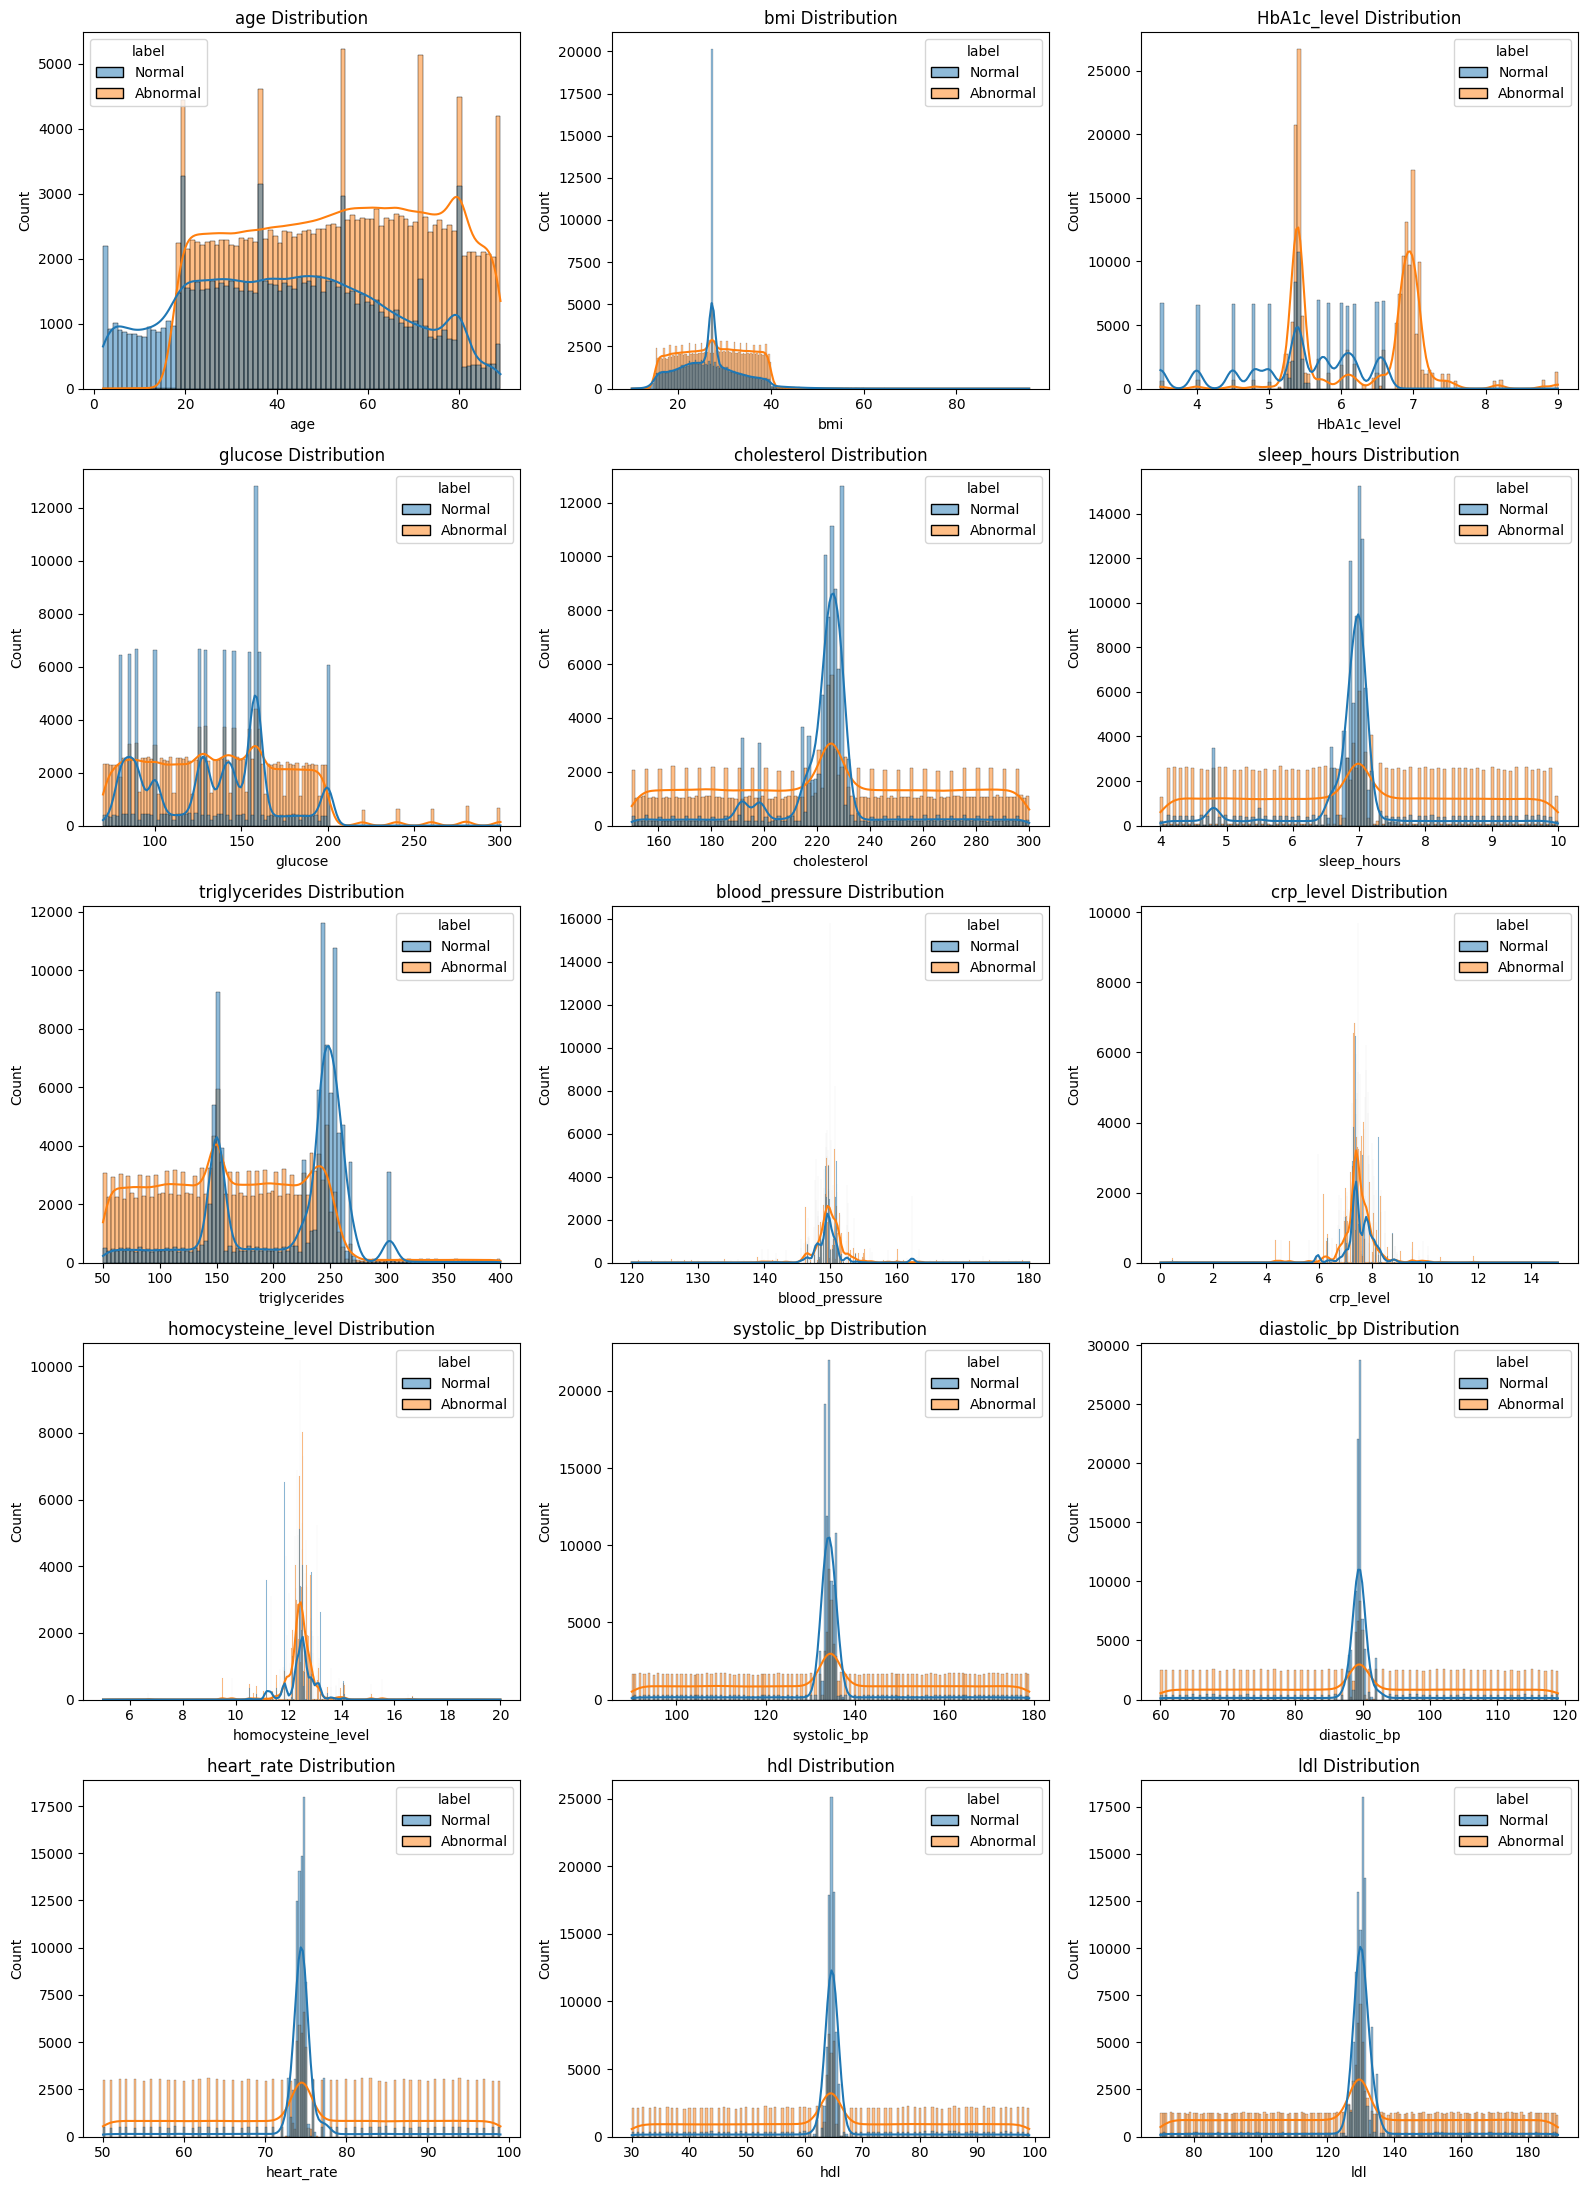

In [12]:
important_numeric = [
    "age",
    "bmi",
    "HbA1c_level",
    "glucose",
    "cholesterol",
    "sleep_hours",
    "triglycerides",
    "blood_pressure",
    "crp_level",
    "homocysteine_level",
    "systolic_bp",
    "diastolic_bp",
    "heart_rate",
    "hdl",
    "ldl"
]

fig, axes = plt.subplots(5, 3, figsize=(16, 22))

for ax, col in zip(axes.flat, important_numeric):
    sns.histplot(data=df, x=col, hue="label", kde=True, ax=ax)
    ax.set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()

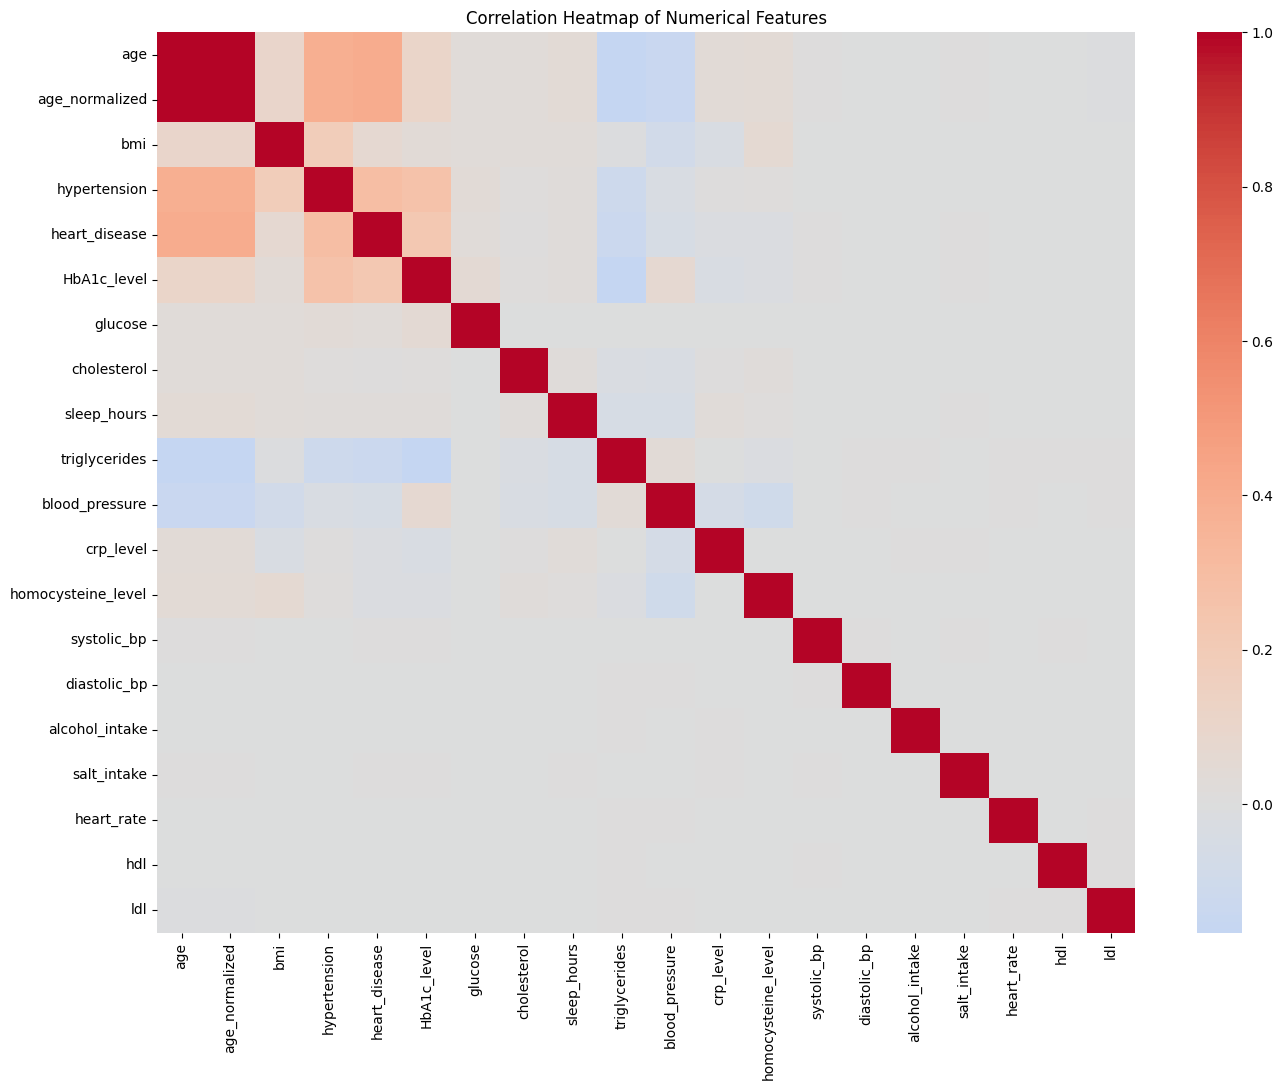

In [13]:
plt.figure(figsize=(14, 11))

correlation = df[numerical_cols].corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

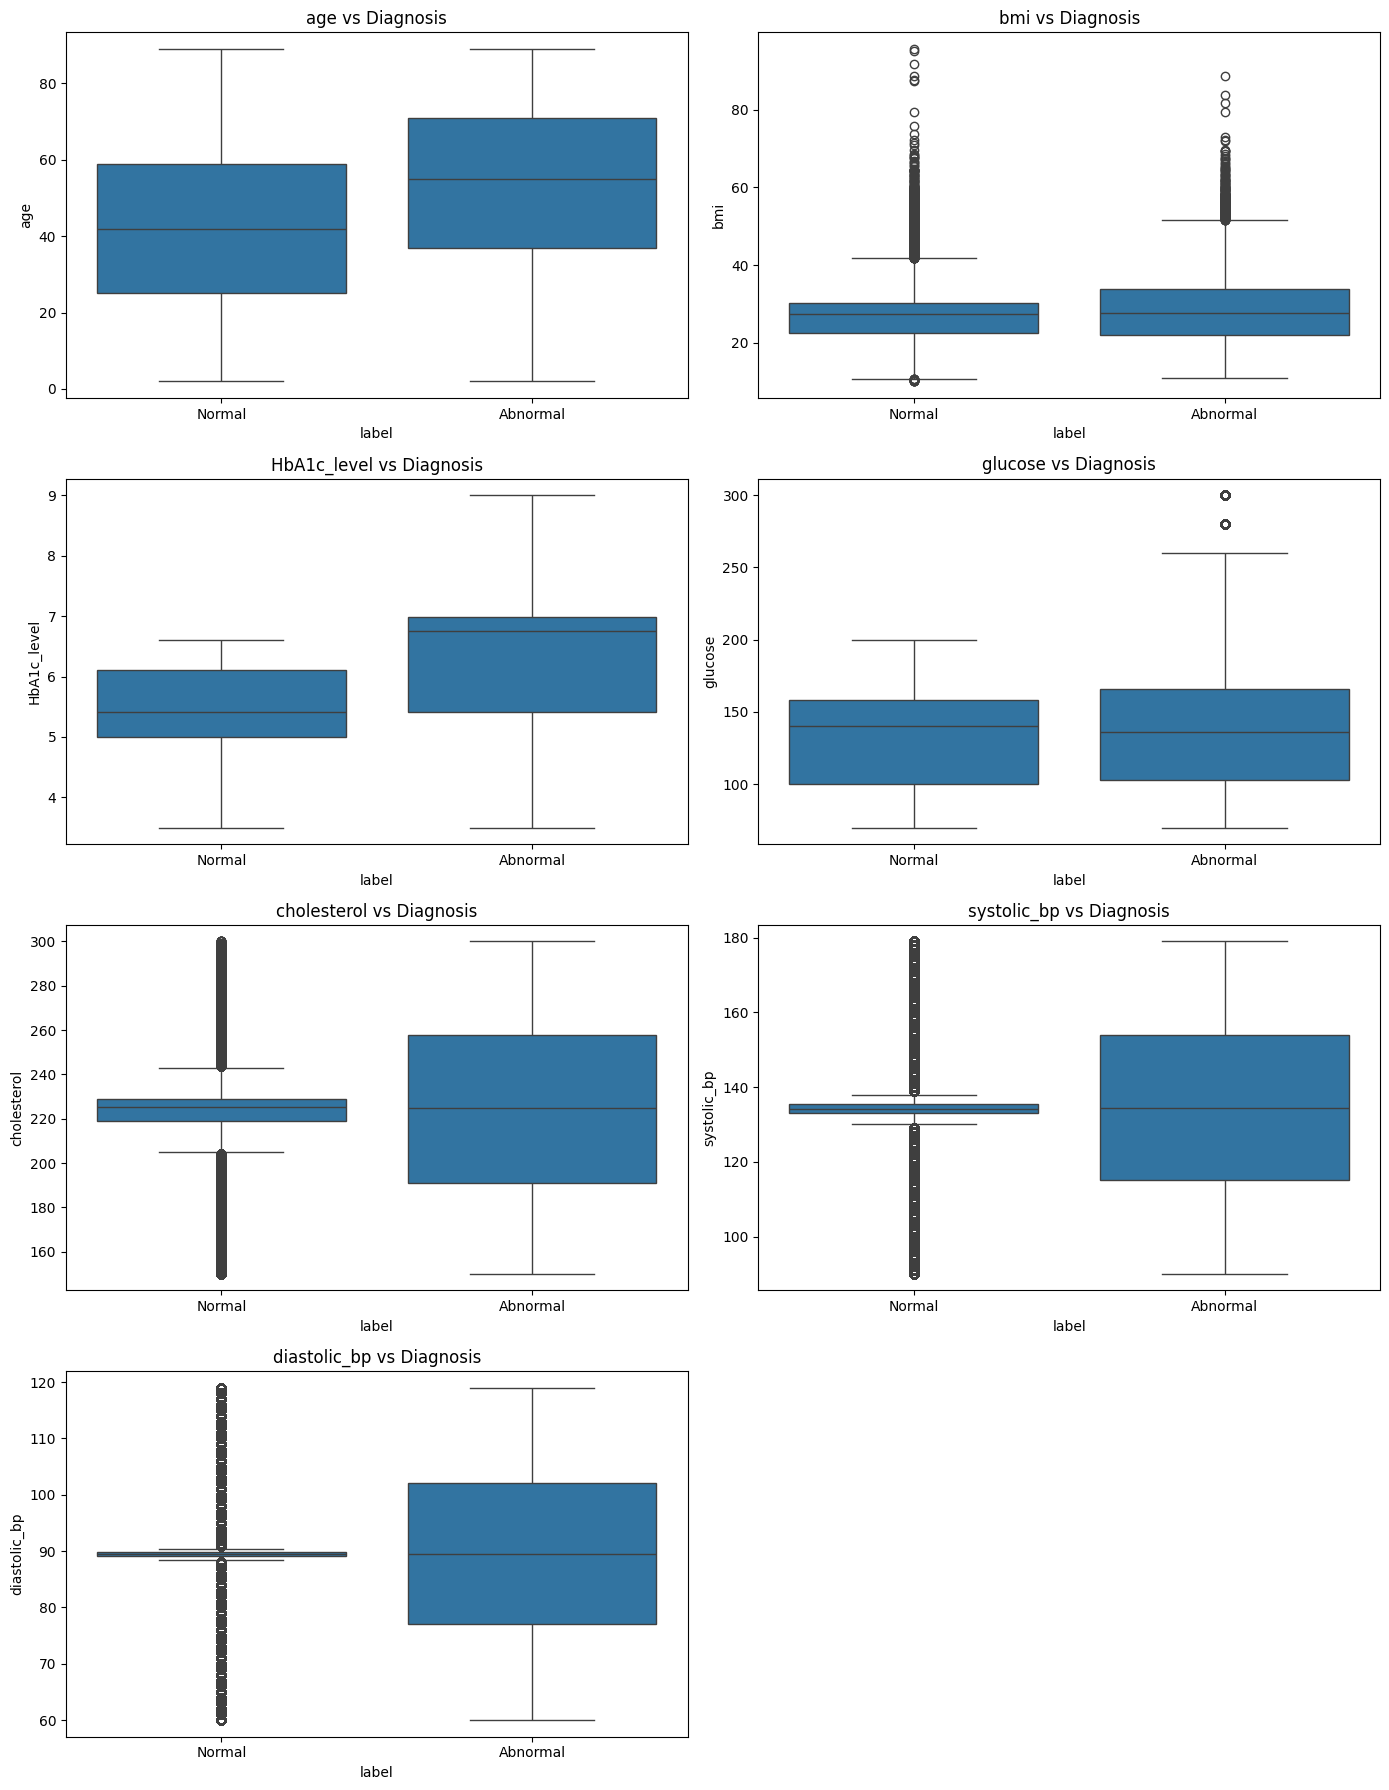

In [14]:
selected_features = [
    "age",
    "bmi",
    "HbA1c_level",
    "glucose",
    "cholesterol",
    "systolic_bp",
    "diastolic_bp"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for ax, col in zip(axes.flat, selected_features):
    sns.boxplot(
        data=df,
        x="label",
        y=col,
        ax=ax
    )
    ax.set_title(f"{col} vs Diagnosis")

# Hide unused subplot
axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [15]:
checks = {
    "age_level → age": ["age_level", "age"],
    "bmi_level → bmi": ["bmi_level", "bmi"],
    "blood_pressure → systolic/diastolic": [
        "blood_pressure",
        "systolic_bp",
        "diastolic_bp"
    ]
}

for name, cols in checks.items():
    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)
    print(df[cols].groupby(cols[0]).agg({
        col: ["min", "max", "mean", "nunique"]
        for col in cols[1:]
    }))


age_level → age
          age                       
          min max       mean nunique
age_level                           
Mature     46  67  56.314953      22
Middle     24  45  34.601249      22
Senior     68  89  77.726451      22
Young       2  23  16.118516      22

bmi_level → bmi
               bmi                              
               min        max       mean nunique
bmi_level                                       
Normal       18.50  24.998857  21.831725    3446
Obese        30.00  95.690000  35.247881    6957
Overweight   25.00  29.998623  27.403208    2827
Underweight  10.01  18.499041  16.628621     892

blood_pressure → systolic/diastolic
               systolic_bp                                 diastolic_bp  \
                       min         max        mean nunique          min   
blood_pressure                                                            
120.0           132.238854  136.912206  134.446818      81    88.353503   
121.0           132.238854 

In [16]:
binary_features = [
    "diabetes",
    "hypertension",
    "heart_disease",
    "family_history",
    "low_hdl_cholesterol",
    "high_ldl_cholesterol",
    "high_blood_pressure"
]

for col in binary_features:
    print(f"\n--- {col} ---")
    print(pd.crosstab(
        df[col],
        df["label"],
        normalize="index"
    ).round(3))


--- diabetes ---
label     Abnormal  Normal
diabetes                  
No           0.407   0.593
Yes          1.000   0.000

--- hypertension ---
label         Abnormal  Normal
hypertension                  
0.000000         0.229   0.771
0.000286         0.682   0.318
0.000300         0.824   0.176
0.000325         0.764   0.236
0.000348         0.706   0.294
...                ...     ...
0.366667         1.000   0.000
0.368421         1.000   0.000
0.407407         1.000   0.000
0.431818         1.000   0.000
1.000000         1.000   0.000

[137 rows x 2 columns]

--- heart_disease ---
label          Abnormal  Normal
heart_disease                  
0.000000          0.312   0.688
0.000300          0.824   0.176
0.000776          0.694   0.306
0.001703          0.712   0.288
0.002018          0.713   0.287
...                 ...     ...
0.312500          1.000   0.000
0.318182          1.000   0.000
0.333333          1.000   0.000
0.347134          1.000   0.000
1.000000          

In [17]:
duplicates = df[df.duplicated(keep=False)].copy()

print("Rows involved in duplicate groups:", len(duplicates))
print("Unique duplicated groups:", duplicates.drop_duplicates().shape[0])

print("\nTarget distribution among duplicated rows:")
print(duplicates["label"].value_counts())

print("\nTarget distribution among duplicated rows (%):")
print(
    duplicates["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Rows involved in duplicate groups: 4529
Unique duplicated groups: 2245

Target distribution among duplicated rows:
label
Normal      4433
Abnormal      96
Name: count, dtype: int64

Target distribution among duplicated rows (%):
label
Normal      97.88
Abnormal     2.12
Name: proportion, dtype: float64


In [18]:
duplicate_groups = (
    df.groupby(list(df.columns.drop("label")), dropna=False)["label"]
    .nunique()
)

print(
    "Duplicate feature combinations with conflicting labels:",
    (duplicate_groups > 1).sum()
)

Duplicate feature combinations with conflicting labels: 0


In [19]:
print("Label distribution by sublabel:")
print(pd.crosstab(
    df["sublabel"],
    df["label"],
    normalize="index"
).round(3))

print("\nDisease flags vs label:")
print(pd.crosstab(
    df["disease_flags"],
    df["label"]
))

Label distribution by sublabel:
label     Abnormal  Normal
sublabel                  
DI             1.0     0.0
DI_HT          1.0     0.0
DI_HT_HY       1.0     0.0
DI_HY          1.0     0.0
HT             1.0     0.0
HT_HY          1.0     0.0
HY             1.0     0.0
N              0.0     1.0

Disease flags vs label:
label          Abnormal  Normal
disease_flags                  
0,0,0                 0  106884
0,0,1             69806       0
0,1,0              2595       0
0,1,1              1066       0
1,0,0             31918       0
1,0,1             66473       0
1,1,0              1398       0
1,1,1               845       0


In [20]:
important_features = [
    "diabetes",
    "hypertension",
    "heart_disease",
    "high_blood_pressure",
    "low_hdl_cholesterol",
    "high_ldl_cholesterol"
]

for col in important_features:
    print(f"\n{'=' * 60}")
    print(col)
    print("=" * 60)
    print("Data type:", df[col].dtype)
    print("Unique values:", df[col].nunique())
    print("Min:", df[col].min())
    print("Max:", df[col].max())
    
    if df[col].nunique() <= 20:
        print("Values:")
        print(df[col].value_counts().sort_index())


diabetes
Data type: object
Unique values: 2
Min: No
Max: Yes
Values:
diabetes
No     180351
Yes    100634
Name: count, dtype: int64

hypertension
Data type: float64
Unique values: 137
Min: 0.0
Max: 1.0

heart_disease
Data type: float64
Unique values: 125
Min: 0.0
Max: 1.0

high_blood_pressure
Data type: object
Unique values: 2
Min: No
Max: Yes
Values:
high_blood_pressure
No     138817
Yes    142168
Name: count, dtype: int64

low_hdl_cholesterol
Data type: object
Unique values: 2
Min: No
Max: Yes
Values:
low_hdl_cholesterol
No     225935
Yes     55050
Name: count, dtype: int64

high_ldl_cholesterol
Data type: object
Unique values: 2
Min: No
Max: Yes
Values:
high_ldl_cholesterol
No     134543
Yes    146442
Name: count, dtype: int64


In [21]:
disease_features = [
    "diabetes",
    "hypertension",
    "heart_disease"
]

for col in disease_features:
    print(f"\n{'=' * 70}")
    print(f"{col} vs sublabel")
    print("=" * 70)
    
    print(
        pd.crosstab(
            df[col],
            df["sublabel"],
            normalize="index"
        ).round(3)
    )


diabetes vs sublabel
sublabel     DI  DI_HT  DI_HT_HY  DI_HY     HT  HT_HY     HY      N
diabetes                                                           
No        0.000  0.000     0.000  0.000  0.014  0.006  0.387  0.593
Yes       0.317  0.014     0.008  0.661  0.000  0.000  0.000  0.000

hypertension vs sublabel
sublabel         DI  DI_HT  DI_HT_HY  DI_HY     HT  HT_HY     HY      N
hypertension                                                           
0.000000      0.082  0.009     0.000  0.078  0.020  0.000  0.040  0.771
0.000286      0.000  0.000     0.000  0.000  0.009  0.000  0.674  0.318
0.000300      0.000  0.000     0.000  0.000  0.000  0.000  0.824  0.176
0.000325      0.000  0.000     0.000  0.000  0.000  0.000  0.764  0.236
0.000348      0.000  0.000     0.000  0.000  0.003  0.003  0.700  0.294
...             ...    ...       ...    ...    ...    ...    ...    ...
0.366667      0.309  0.005     0.011  0.675  0.000  0.000  0.000  0.000
0.368421      0.289  0.005     0

In [22]:
print("Disease flags → sublabel")
print(
    pd.crosstab(
        df["disease_flags"],
        df["sublabel"]
    )
)

print("\nSublabel → disease flags")
print(
    pd.crosstab(
        df["sublabel"],
        df["disease_flags"]
    )
)

Disease flags → sublabel
sublabel          DI  DI_HT  DI_HT_HY  DI_HY    HT  HT_HY     HY       N
disease_flags                                                           
0,0,0              0      0         0      0     0      0      0  106884
0,0,1              0      0         0      0     0      0  69806       0
0,1,0              0      0         0      0  2595      0      0       0
0,1,1              0      0         0      0     0   1066      0       0
1,0,0          31918      0         0      0     0      0      0       0
1,0,1              0      0         0  66473     0      0      0       0
1,1,0              0   1398         0      0     0      0      0       0
1,1,1              0      0       845      0     0      0      0       0

Sublabel → disease flags
disease_flags   0,0,0  0,0,1  0,1,0  0,1,1  1,0,0  1,0,1  1,1,0  1,1,1
sublabel                                                              
DI                  0      0      0      0  31918      0      0      0
DI_HT 

In [23]:
bp_cols = [
    "blood_pressure",
    "systolic_bp",
    "diastolic_bp",
    "high_blood_pressure"
]

print(df[bp_cols].describe().T)

print("\nCorrelations:")
print(df[bp_cols].corr(numeric_only=True).round(3))

                   count        mean        std    min         25%  \
blood_pressure  280985.0  149.887200   4.148644  120.0  148.946429   
systolic_bp     280985.0  134.405105  20.542140   90.0  126.000000   
diastolic_bp    280985.0   89.476720  13.667219   60.0   84.000000   

                       50%         75%    max  
blood_pressure  149.713320  150.720942  180.0  
systolic_bp     134.167413  143.000000  179.0  
diastolic_bp     89.504587   95.000000  119.0  

Correlations:
                blood_pressure  systolic_bp  diastolic_bp
blood_pressure           1.000       -0.004         0.008
systolic_bp             -0.004        1.000         0.003
diastolic_bp             0.008        0.003         1.000


In [24]:
print("Source datasets:")
print(df["source_dataset"].value_counts())

print("\nComposite key examples:")
print(df["composite_key"].head(20).to_string(index=False))

Source datasets:
source_dataset
hypertension    174982
diabetes         96128
heart             9875
Name: count, dtype: int64

Composite key examples:
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
Young_Female_Normal_Never_No
 Young_Female_Obese_Never_No
 Young_Female_Obese_Never_No
 Young_Female_Obese_Never_No


In [25]:
for col in ["hypertension", "heart_disease"]:
    print(f"\n{'=' * 70}")
    print(col)
    print("=" * 70)

    print("Lowest values:")
    print(df[col].value_counts().sort_index().head(20))

    print("\nHighest values:")
    print(df[col].value_counts().sort_index().tail(20))

    print("\nExact integer-like values:")
    print(
        df[col][df[col].isin([0.0, 1.0])]
        .value_counts()
        .sort_index()
    )


hypertension
Lowest values:
hypertension
0.000000    106307
0.000286       340
0.000300       199
0.000325       144
0.000348       340
0.001001       263
0.003086       230
0.003484       666
0.003494       255
0.004258      1283
0.004566       621
0.005319       644
0.005348       531
0.006061       546
0.006897       477
0.007042      1225
0.007576       383
0.010091      1259
0.010676      1097
0.010753      1251
Name: count, dtype: int64

Highest values:
hypertension
0.267857    1257
0.277344     972
0.281250    1914
0.281330    1890
0.282895    1979
0.285406     589
0.285714    1474
0.288288    1803
0.296651     910
0.297017    1872
0.300000    1141
0.303226    1218
0.318841    1912
0.328947    1847
0.333333    3597
0.366667    1292
0.368421    1903
0.407407    1771
0.431818     973
1.000000    8081
Name: count, dtype: int64

Exact integer-like values:
hypertension
0.0    106307
1.0      8081
Name: count, dtype: int64

heart_disease
Lowest values:
heart_disease
0.000000    12165

In [26]:
print("=" * 70)
print("DIABETES BY SOURCE DATASET")
print("=" * 70)

print(
    pd.crosstab(
        df["source_dataset"],
        df["diabetes"],
        normalize="index"
    ).round(3)
)

for col in ["hypertension", "heart_disease"]:

    print(f"\n{'=' * 70}")
    print(f"{col} BY SOURCE DATASET")
    print("=" * 70)

    print(
        df.groupby("source_dataset")[col]
        .agg(
            min="min",
            max="max",
            mean="mean",
            unique_values="nunique"
        )
        .round(4)
    )

DIABETES BY SOURCE DATASET
diabetes           No    Yes
source_dataset              
diabetes        0.912  0.088
heart           0.503  0.497
hypertension    0.501  0.499

hypertension BY SOURCE DATASET
                min     max    mean  unique_values
source_dataset                                    
diabetes        0.0  1.0000  0.0776              2
heart           0.0  0.4318  0.1532             93
hypertension    0.0  1.0000  0.1546            137

heart_disease BY SOURCE DATASET
                min     max    mean  unique_values
source_dataset                                    
diabetes        0.0  1.0000  0.0408              2
heart           0.0  0.3333  0.0789             83
hypertension    0.0  0.3471  0.0910            124


In [27]:
source_features = [
    "source_dataset",
    "diabetes",
    "hypertension",
    "heart_disease",
    "high_blood_pressure",
    "low_hdl_cholesterol",
    "high_ldl_cholesterol"
]

print(
    df[source_features]
    .groupby("source_dataset")
    .agg({
        "diabetes": lambda x: x.value_counts().to_dict(),
        "hypertension": ["min", "max", "mean", "nunique"],
        "heart_disease": ["min", "max", "mean", "nunique"],
        "high_blood_pressure": lambda x: x.value_counts().to_dict(),
        "low_hdl_cholesterol": lambda x: x.value_counts().to_dict(),
        "high_ldl_cholesterol": lambda x: x.value_counts().to_dict()
    })
)

                                   diabetes hypertension                      \
                                   <lambda>          min       max      mean   
source_dataset                                                                 
diabetes         {'No': 87646, 'Yes': 8482}          0.0  1.000000  0.077615   
heart             {'No': 4967, 'Yes': 4908}          0.0  0.431818  0.153176   
hypertension    {'No': 87738, 'Yes': 87244}          0.0  1.000000  0.154608   

                       heart_disease                              \
               nunique           min       max      mean nunique   
source_dataset                                                     
diabetes             2           0.0  1.000000  0.040810       2   
heart               93           0.0  0.333333  0.078897      83   
hypertension       137           0.0  0.347134  0.090978     124   

                         high_blood_pressure           low_hdl_cholesterol  \
                                

In [28]:
excluded_features = [
    "composite_key",
    "source_dataset",
    "disease_flags",
    "sublabel",
    "label",
    "diabetes",
    "hypertension",
    "heart_disease",
    "high_blood_pressure"
]

candidate_features = [
    col for col in df.columns
    if col not in excluded_features
]

print("Candidate features:")
for i, col in enumerate(candidate_features, 1):
    print(f"{i}. {col}")

print("\nTotal candidate features:", len(candidate_features))

print("\nData types:")
print(df[candidate_features].dtypes)

print("\nMissing values:")
print(df[candidate_features].isnull().sum().sum())

Candidate features:
1. age_level
2. gender
3. bmi_level
4. smoking
5. age
6. age_normalized
7. bmi
8. HbA1c_level
9. glucose
10. cholesterol
11. sleep_hours
12. triglycerides
13. physical_activity
14. family_history
15. stress_level
16. low_hdl_cholesterol
17. high_ldl_cholesterol
18. blood_pressure
19. sugar_consumption
20. crp_level
21. homocysteine_level
22. systolic_bp
23. diastolic_bp
24. alcohol_intake
25. salt_intake
26. heart_rate
27. hdl
28. ldl
29. education_level
30. employment_status

Total candidate features: 30

Data types:
age_level                object
gender                   object
bmi_level                object
smoking                  object
age                       int64
age_normalized          float64
bmi                     float64
HbA1c_level             float64
glucose                 float64
cholesterol             float64
sleep_hours             float64
triglycerides           float64
physical_activity        object
family_history           object
stress_l

In [29]:
# Check relationships between derived and original features

print("Age relationship:")
print(
    df.groupby("age_level")["age"]
      .agg(["min", "max", "mean", "count"])
)

print("\nBMI relationship:")
print(
    df.groupby("bmi_level")["bmi"]
      .agg(["min", "max", "mean", "count"])
)

print("\nAge vs age_normalized correlation:")
print(df[["age", "age_normalized"]].corr())

print("\nNumeric feature correlations with target:")
target_numeric = df["label"].map({
    "Normal": 0,
    "Abnormal": 1
})

numeric_features = df[candidate_features].select_dtypes(
    include=np.number
).columns

correlations = (
    df[numeric_features]
    .corrwith(target_numeric)
    .sort_values(key=abs, ascending=False)
)

print(correlations)

Age relationship:
           min  max       mean  count
age_level                            
Mature      46   67  56.314953  87632
Middle      24   45  34.601249  85344
Senior      68   89  77.726451  70225
Young        2   23  16.118516  37784

BMI relationship:
               min        max       mean  count
bmi_level                                      
Normal       18.50  24.998857  21.831725  70596
Obese        30.00  95.690000  35.247881  98377
Overweight   25.00  29.998623  27.403208  79172
Underweight  10.01  18.499041  16.628621  32840

Age vs age_normalized correlation:
                age  age_normalized
age             1.0             1.0
age_normalized  1.0             1.0

Numeric feature correlations with target:
HbA1c_level           0.452993
triglycerides        -0.361667
age                   0.257273
age_normalized        0.257273
bmi                   0.070310
glucose               0.046262
sleep_hours           0.036169
crp_level            -0.035353
cholesterol 

In [30]:
categorical_features = [
    "gender",
    "smoking",
    "physical_activity",
    "family_history",
    "stress_level",
    "low_hdl_cholesterol",
    "high_ldl_cholesterol",
    "sugar_consumption",
    "education_level",
    "employment_status"
]

for col in categorical_features:
    print("\n" + "=" * 70)
    print(f"{col} vs Diagnosis")
    print("=" * 70)

    result = pd.crosstab(
        df[col],
        df["label"],
        normalize="index"
    ).round(3)

    print(result)


gender vs Diagnosis
label   Abnormal  Normal
gender                  
Female     0.589   0.411
Male       0.654   0.346

smoking vs Diagnosis
label    Abnormal  Normal
smoking                  
Current     0.770   0.230
Former      0.700   0.300
Never       0.483   0.517

physical_activity vs Diagnosis
label              Abnormal  Normal
physical_activity                  
High                  0.516   0.484
Low                   0.697   0.303
Moderate              0.697   0.303

family_history vs Diagnosis
label           Abnormal  Normal
family_history                  
No                 0.572   0.428
Yes                0.681   0.319

stress_level vs Diagnosis
label         Abnormal  Normal
stress_level                  
High             0.586   0.414
Low              0.640   0.360
Medium           0.637   0.363

low_hdl_cholesterol vs Diagnosis
label                Abnormal  Normal
low_hdl_cholesterol                  
No                      0.640   0.360
Yes                     

In [31]:
from sklearn.model_selection import train_test_split

# Final target
X = df.drop(columns=[
    "label",
    "disease_flags",
    "sublabel",
    "composite_key",
    "source_dataset",
    "age_normalized",
    "diabetes",
    "hypertension",
    "heart_disease"
])

y = df["label"].map({
    "Normal": 0,
    "Abnormal": 1
})

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

X shape: (280985, 30)
y shape: (280985,)

Target distribution:
label
1    174101
0    106884
Name: count, dtype: int64

Target distribution (%):
label
1    61.96
0    38.04
Name: proportion, dtype: float64

Training samples: 224788
Testing samples: 56197


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully.")

Numerical features: 17
['age', 'bmi', 'HbA1c_level', 'glucose', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl']

Categorical features: 13
['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'high_blood_pressure', 'sugar_consumption', 'education_level', 'employment_status']

Preprocessing pipeline created successfully.


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline

# ============================================================
# 1. Logistic Regression
# ============================================================

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression pipeline created.")


# ============================================================
# 2. Random Forest
# ============================================================

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created.")


# ============================================================
# 3. Gradient Boosting
# ============================================================

gradient_boosting_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingClassifier(
                random_state=42
            )
        )
    ]
)

print("Gradient Boosting pipeline created.")

Logistic Regression pipeline created.
Random Forest pipeline created.
Gradient Boosting pipeline created.


In [34]:
import time

print("=" * 70)
print("TRAINING: LOGISTIC REGRESSION")
print("=" * 70)

start_time = time.time()

logistic_pipeline.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"\nTraining completed successfully.")
print(f"Training time: {training_time:.2f} seconds")

TRAINING: LOGISTIC REGRESSION

Training completed successfully.
Training time: 2.97 seconds


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("EVALUATION: LOGISTIC REGRESSION")
print("=" * 70)

# Predictions
y_pred = logistic_pipeline.predict(X_test)

# Probability for ROC-AUC
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"\nAccuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Abnormal"]
    )
)

EVALUATION: LOGISTIC REGRESSION

Accuracy : 0.7774
Precision: 0.7968
Recall   : 0.8600
F1 Score : 0.8272
ROC-AUC  : 0.8635

Confusion Matrix:
[[13739  7638]
 [ 4874 29946]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.74      0.64      0.69     21377
    Abnormal       0.80      0.86      0.83     34820

    accuracy                           0.78     56197
   macro avg       0.77      0.75      0.76     56197
weighted avg       0.77      0.78      0.77     56197



In [36]:
print("=" * 70)
print("TRAINING: RANDOM FOREST")
print("=" * 70)

start_time = time.time()

random_forest_pipeline.fit(X_train, y_train)

rf_training_time = time.time() - start_time

print("\nTraining completed successfully.")
print(f"Training time: {rf_training_time:.2f} seconds")

TRAINING: RANDOM FOREST

Training completed successfully.
Training time: 31.78 seconds


In [37]:
print("=" * 70)
print("EVALUATION: RANDOM FOREST")
print("=" * 70)

start_time = time.time()

y_pred_rf = random_forest_pipeline.predict(X_test)
y_prob_rf = random_forest_pipeline.predict_proba(X_test)[:, 1]

evaluation_time = time.time() - start_time

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f"\nAccuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")
print(f"Prediction time: {evaluation_time:.2f} seconds")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Normal", "Abnormal"]
    )
)

EVALUATION: RANDOM FOREST

Accuracy : 0.8793
Precision: 0.8632
Recall   : 0.9568
F1 Score : 0.9076
ROC-AUC  : 0.9383
Prediction time: 2.03 seconds

Confusion Matrix:
[[16097  5280]
 [ 1504 33316]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.91      0.75      0.83     21377
    Abnormal       0.86      0.96      0.91     34820

    accuracy                           0.88     56197
   macro avg       0.89      0.85      0.87     56197
weighted avg       0.88      0.88      0.88     56197



In [38]:
import time

print("=" * 70)
print("TRAINING: GRADIENT BOOSTING")
print("=" * 70)

start_time = time.time()

gradient_boosting_pipeline.fit(X_train, y_train)

gb_training_time = time.time() - start_time

print("\nTraining completed successfully.")
print(f"Training time: {gb_training_time:.2f} seconds")

TRAINING: GRADIENT BOOSTING

Training completed successfully.
Training time: 138.59 seconds


In [39]:
print("=" * 70)
print("EVALUATION: GRADIENT BOOSTING")
print("=" * 70)

start_time = time.time()

y_pred_gb = gradient_boosting_pipeline.predict(X_test)
y_prob_gb = gradient_boosting_pipeline.predict_proba(X_test)[:, 1]

prediction_time = time.time() - start_time

accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb)
recall_gb = recall_score(y_test, y_pred_gb)
f1_gb = f1_score(y_test, y_pred_gb)
roc_auc_gb = roc_auc_score(y_test, y_prob_gb)

print(f"\nAccuracy  : {accuracy_gb:.4f}")
print(f"Precision : {precision_gb:.4f}")
print(f"Recall    : {recall_gb:.4f}")
print(f"F1 Score  : {f1_gb:.4f}")
print(f"ROC-AUC   : {roc_auc_gb:.4f}")
print(f"Prediction time: {prediction_time:.2f} seconds")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_gb,
        target_names=["Normal", "Abnormal"]
    )
)

EVALUATION: GRADIENT BOOSTING

Accuracy  : 0.8761
Precision : 0.8669
Recall    : 0.9451
F1 Score  : 0.9043
ROC-AUC   : 0.9349
Prediction time: 0.82 seconds

Confusion Matrix:
[[16326  5051]
 [ 1911 32909]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.90      0.76      0.82     21377
    Abnormal       0.87      0.95      0.90     34820

    accuracy                           0.88     56197
   macro avg       0.88      0.85      0.86     56197
weighted avg       0.88      0.88      0.87     56197



In [40]:
# ============================================================
# MODEL COMPARISON
# ============================================================

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy,
        accuracy_rf,
        accuracy_gb
    ],
    "Precision": [
        precision,
        precision_rf,
        precision_gb
    ],
    "Recall": [
        recall,
        recall_rf,
        recall_gb
    ],
    "F1 Score": [
        f1,
        f1_rf,
        f1_gb
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_rf,
        roc_auc_gb
    ]
})

model_results = model_results.round(4)

print("MODEL PERFORMANCE COMPARISON")
print("=" * 80)
display(model_results)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7774,0.7968,0.8600,0.8272,0.8635
1,Random Forest,0.8793,0.8632,0.9568,0.9076,0.9383
2,Gradient Boosting,0.8761,0.8669,0.9451,0.9043,0.9349


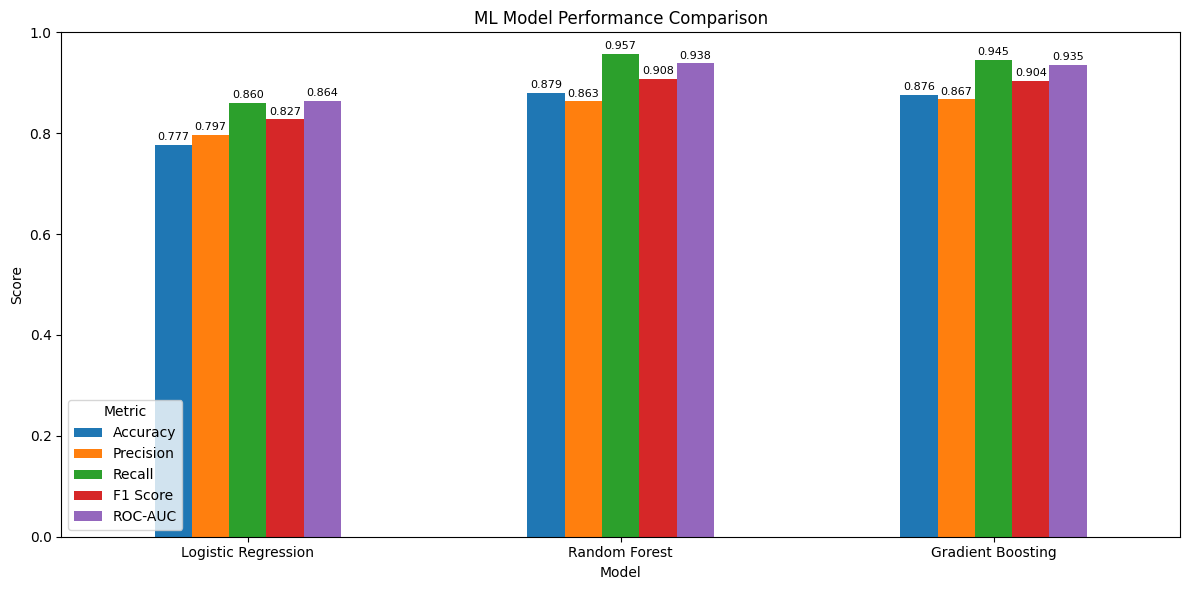

In [41]:
# ============================================================
# MODEL PERFORMANCE COMPARISON - VISUALIZATION
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_plot = model_results.set_index("Model")[metrics]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("ML Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.0)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=2,
        fontsize=8
    )

plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [42]:
# Check the actual steps inside the Random Forest pipeline

print("Random Forest Pipeline Steps:")
print("=" * 50)

for name, step in random_forest_pipeline.named_steps.items():
    print(f"{name} -> {type(step).__name__}")

Random Forest Pipeline Steps:
preprocessor -> ColumnTransformer
model -> RandomForestClassifier


In [43]:
# ============================================================
# RANDOM FOREST - FEATURE IMPORTANCE
# ============================================================

# Get fitted Random Forest model
rf_model = random_forest_pipeline.named_steps["model"]

# Get preprocessing pipeline
preprocessor = random_forest_pipeline.named_steps["preprocessor"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest feature importance
importances = rf_model.feature_importances_

# Create feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    by="Importance",
    ascending=False
)

print("TOP 20 MOST IMPORTANT FEATURES")
print("=" * 60)

display(feature_importance_df.head(20))

TOP 20 MOST IMPORTANT FEATURES


,Feature,Importance
2,num__HbA1c_level,0.178702
6,num__triglycerides,0.083294
10,num__systolic_bp,0.060512
5,num__sleep_hours,0.057674
13,num__salt_intake,0.053311
1,num__bmi,0.052750
15,num__hdl,0.052440
12,num__alcohol_intake,0.050538
0,num__age,0.047197
4,num__cholesterol,0.046963


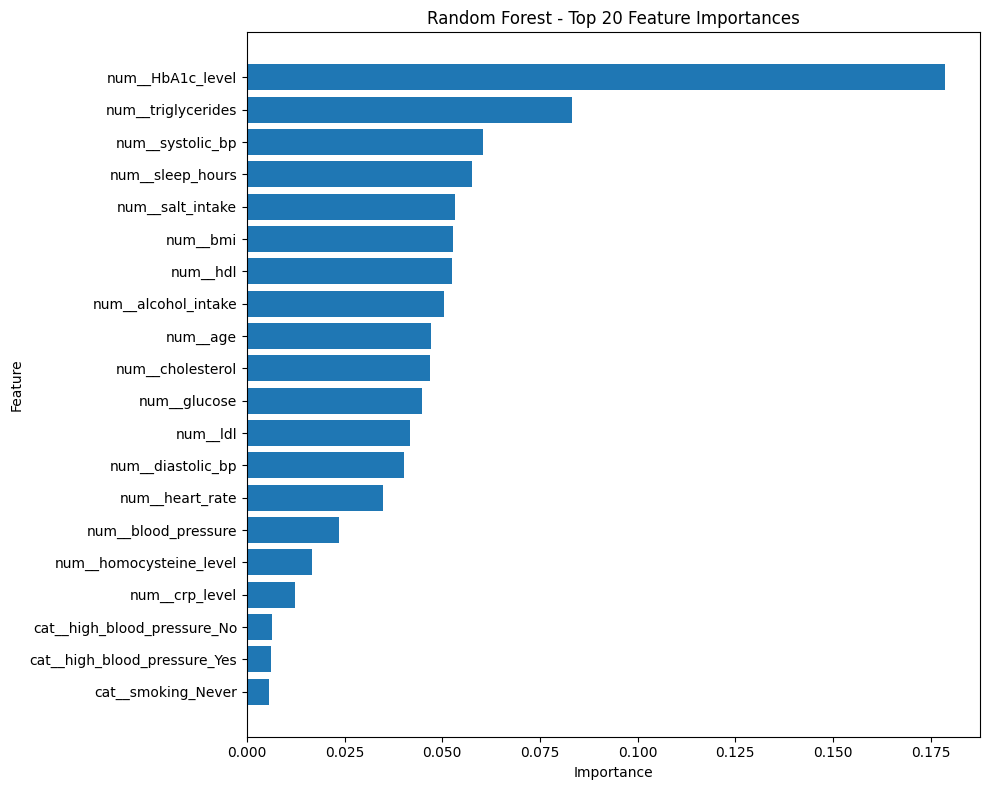

In [44]:
# ============================================================
# RANDOM FOREST - TOP 20 FEATURE IMPORTANCE VISUALIZATION
# ============================================================

top_features = feature_importance_df.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Random Forest - Top 20 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [45]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.49.1


c:\Users\aquil\AI-Medical-Diagnosis-Platform\aipp\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [46]:
# ============================================================
# SHAP - PREPARE RANDOM FOREST MODEL
# ============================================================

# Extract fitted Random Forest and preprocessor
rf_model = random_forest_pipeline.named_steps["model"]
preprocessor = random_forest_pipeline.named_steps["preprocessor"]

# Transform the test data using the SAME preprocessing
X_test_transformed = preprocessor.transform(X_test)

# Get feature names after preprocessing
shap_feature_names = preprocessor.get_feature_names_out()

print("SHAP preparation completed.")
print("Original test shape:", X_test.shape)
print("Transformed test shape:", X_test_transformed.shape)
print("Number of SHAP features:", len(shap_feature_names))

SHAP preparation completed.
Original test shape: (56197, 30)
Transformed test shape: (56197, 53)
Number of SHAP features: 53


In [47]:
# ============================================================
# SHAP TREE EXPLAINER
# ============================================================

explainer = shap.TreeExplainer(rf_model)

print("SHAP TreeExplainer created successfully.")

SHAP TreeExplainer created successfully.


In [48]:
# ============================================================
# SHAP - CALCULATE VALUES
# ============================================================

SHAP_SAMPLE_SIZE = 200

X_shap = X_test_transformed[:SHAP_SAMPLE_SIZE]

print("Calculating SHAP values...")
print(f"Samples used: {X_shap.shape[0]}")
print(f"Features used: {X_shap.shape[1]}")

shap_values = explainer.shap_values(
    X_shap,
    check_additivity=False
)

print("\nSHAP values calculated successfully.")

if isinstance(shap_values, list):
    print("SHAP output type: list")
    print("Class 0 shape:", shap_values[0].shape)
    print("Class 1 shape:", shap_values[1].shape)
else:
    print("SHAP output shape:", shap_values.shape)

Calculating SHAP values...
Samples used: 200
Features used: 53

SHAP values calculated successfully.
SHAP output shape: (200, 53, 2)


In [49]:
# ============================================================
# SHAP - GLOBAL FEATURE IMPORTANCE
# ============================================================

# Use SHAP values for the Abnormal class (class 1)
shap_class_1 = shap_values[:, :, 1]

# Calculate mean absolute SHAP value for each feature
mean_abs_shap = np.abs(shap_class_1).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": shap_feature_names,
    "Mean_Abs_SHAP": mean_abs_shap
}).sort_values(
    by="Mean_Abs_SHAP",
    ascending=False
)

print("=" * 70)
print("TOP 20 FEATURES BY SHAP IMPORTANCE")
print("=" * 70)

display(shap_importance_df.head(20))

TOP 20 FEATURES BY SHAP IMPORTANCE


,Feature,Mean_Abs_SHAP
2,num__HbA1c_level,0.112325
6,num__triglycerides,0.037347
10,num__systolic_bp,0.026408
5,num__sleep_hours,0.023785
13,num__salt_intake,0.022963
15,num__hdl,0.021833
12,num__alcohol_intake,0.020439
0,num__age,0.018867
4,num__cholesterol,0.018564
7,num__blood_pressure,0.017141


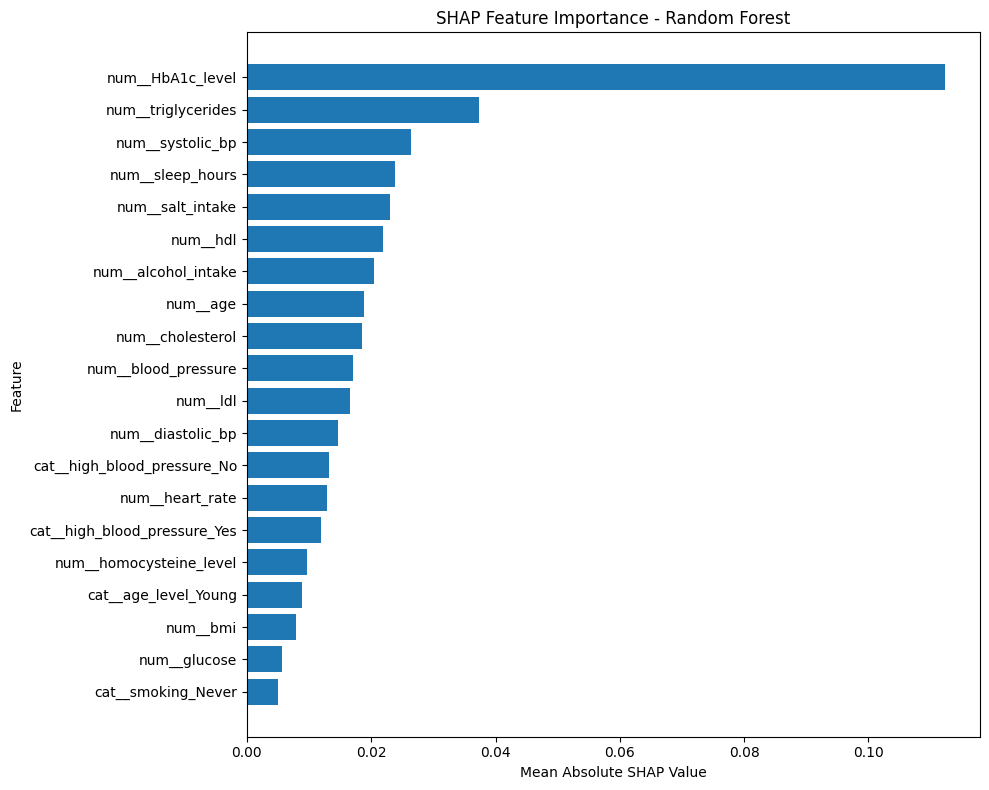

In [50]:
# ============================================================
# SHAP - GLOBAL FEATURE IMPORTANCE PLOT
# ============================================================

top_n = 20

top_features = shap_importance_df.head(top_n).sort_values(
    by="Mean_Abs_SHAP",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Mean_Abs_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("SHAP Feature Importance - Random Forest")

plt.tight_layout()
plt.show()

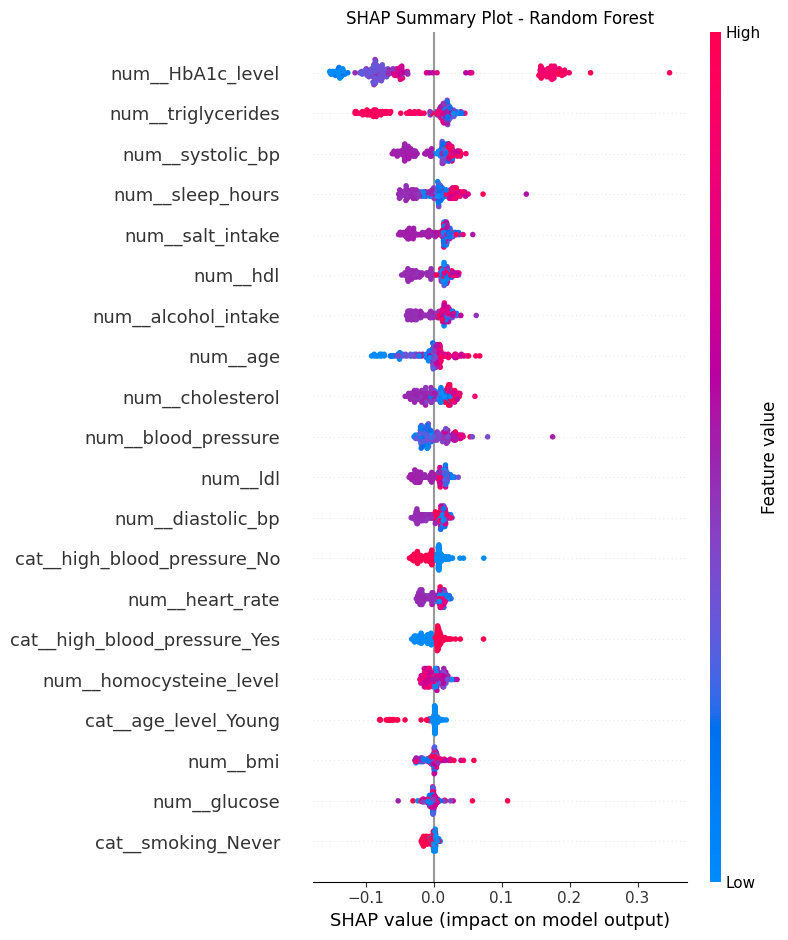

In [51]:
# ============================================================
# SHAP - SUMMARY / BEESWARM PLOT
# ============================================================

# SHAP values for Abnormal class (class 1)
shap_class_1 = shap_values[:, :, 1]

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_class_1,
    X_shap,
    feature_names=shap_feature_names,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot - Random Forest")
plt.tight_layout()
plt.show()

In [52]:
# ============================================================
# SAVE FINAL ML MODEL
# ============================================================

import os
import joblib

# Create model directory if it doesn't exist
MODEL_DIR = "../models/ml"
os.makedirs(MODEL_DIR, exist_ok=True)

# Path for the complete pipeline
MODEL_PATH = os.path.join(
    MODEL_DIR,
    "clinical_disease_random_forest.joblib"
)

# Save the complete pipeline
joblib.dump(
    random_forest_pipeline,
    MODEL_PATH
)

print("=" * 70)
print("FINAL ML MODEL SAVED")
print("=" * 70)
print(f"Model: Random Forest")
print(f"Path: {MODEL_PATH}")
print("Includes: Preprocessing + Random Forest classifier")

FINAL ML MODEL SAVED
Model: Random Forest
Path: ../models/ml\clinical_disease_random_forest.joblib
Includes: Preprocessing + Random Forest classifier


In [53]:
# ============================================================
# VERIFY SAVED MODEL
# ============================================================

loaded_model = joblib.load(MODEL_PATH)

print("=" * 70)
print("MODEL LOAD VERIFICATION")
print("=" * 70)

print("Model loaded successfully.")
print(f"Model type: {type(loaded_model).__name__}")
print(f"Pipeline steps: {list(loaded_model.named_steps.keys())}")

MODEL LOAD VERIFICATION
Model loaded successfully.
Model type: Pipeline
Pipeline steps: ['preprocessor', 'model']


In [54]:
# ============================================================
# TEST MODEL WITH A SAMPLE PATIENT
# ============================================================

# Take one patient from the test set
sample_patient = X_test.iloc[[0]].copy()
actual_label = y_test.iloc[0]

# Make prediction
predicted_label = loaded_model.predict(sample_patient)[0]

# Get prediction probability
prediction_probability = loaded_model.predict_proba(sample_patient)[0]

print("=" * 70)
print("SAMPLE PATIENT PREDICTION")
print("=" * 70)

print(f"Actual diagnosis   : {actual_label}")
print(f"Predicted diagnosis: {predicted_label}")

print("\nPrediction probabilities:")

for class_name, probability in zip(
    loaded_model.classes_,
    prediction_probability
):
    print(f"{class_name}: {probability:.4f}")

SAMPLE PATIENT PREDICTION
Actual diagnosis   : 0
Predicted diagnosis: 0

Prediction probabilities:
0: 0.9300
1: 0.0700


In [55]:
# ============================================================
# VERIFY MODEL FILE
# ============================================================

print("=" * 70)
print("MODEL FILE VERIFICATION")
print("=" * 70)

if os.path.exists(MODEL_PATH):
    file_size_mb = os.path.getsize(MODEL_PATH) / (1024 * 1024)

    print("Model file exists: YES")
    print(f"File size: {file_size_mb:.2f} MB")
    print(f"Location: {MODEL_PATH}")
else:
    print("Model file exists: NO")

MODEL FILE VERIFICATION
Model file exists: YES
File size: 682.04 MB
Location: ../models/ml\clinical_disease_random_forest.joblib
